# C01-DB — DBSCAN trên RFM + AOV + Diversity (log1p + Standard + PCA 90%)

Thí nghiệm **C01-DB** (người chạy: An) theo chiến lược model. So với B01, **chỉ thêm 2 feature hành vi cấp khách**: **AOV** (avg_order_value) và **Diversity** (n_stock_codes — số mã hàng khác nhau đã mua). Đây là nhánh chính C cho DBSCAN.

## Params

In [1]:
FEATURES_B01 = ["Recency", "Frequency", "Monetary"]
FEATURES = FEATURES_B01 + ["AOV", "Diversity"]     # C01: thêm AOV và Diversity
PCA_VAR = 0.90
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]           # giống A01-DB, B01-DB, C04-DB
EPS_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0, 2.5, 3.0]  # mở rộng do thêm biến, khoảng cách lớn hơn
MAX_NOISE = 0.05
MIN_CLUSTERS = 2

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

def find(rel):
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm; đổi tên cột sang tên dùng trong chiến lược model (giống C01-GN, C02-KM, C04-DB của Nguyên)
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figure"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns={
    "avg_order_value": "AOV", "n_stock_codes": "Diversity",
    "avg_quantity_per_order": "QtyPerOrder", "observed_span_days": "Tenure"})
X = df[FEATURES].copy()
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 5)


,Recency,Frequency,Monetary,AOV,Diversity
count,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49
std,99.98,7.64,8441.89,466.49,85.31
min,1.00,1.00,2.90,2.90,1.00
25%,18.00,1.00,301.52,175.47,16.00
50%,51.00,2.00,657.90,286.70,35.00
75%,143.00,5.00,1624.10,421.99,77.00
max,374.00,206.00,278748.02,14844.77,1784.00


**Nhận xét:** 4.327 khách, 5 feature, không thiếu giá trị, không có giá trị âm (đủ điều kiện log1p). AOV trung vị 286,7 nhưng max 14.844,8; Diversity trung vị 35 mã hàng nhưng max 1.784 — cả hai đều lệch phải mạnh như Monetary.

## Kiểm tra AOV có độc lập với Frequency, Monetary không

Về công thức, `AOV = Monetary / Frequency`, nên cần biết `log1p(AOV)` có bị `log1p(Frequency)`, `log1p(Monetary)` giải thích gần hết hay không trước khi đưa cả 3 vào cùng mô hình.

In [3]:
L = np.log1p(X)
A = np.c_[np.ones(len(L)), L["Frequency"], L["Monetary"]]
beta = np.linalg.lstsq(A, L["AOV"], rcond=None)[0]
r2 = 1 - ((L["AOV"] - A @ beta) ** 2).sum() / ((L["AOV"] - L["AOV"].mean()) ** 2).sum()
print(f"R² của log1p(AOV) theo log1p(Frequency), log1p(Monetary): {r2:.4f}")
pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": L.skew()}).round(2)

R² của log1p(AOV) theo log1p(Frequency), log1p(Monetary): 0.9832


,skew_raw,skew_log1p
Recency,1.25,-0.33
Frequency,11.95,1.21
Monetary,21.04,0.35
AOV,11.94,-0.00
Diversity,6.92,-0.24


**Nhận xét:** `log1p(AOV)` được `log1p(Frequency)` và `log1p(Monetary)` giải thích tới 98,32% phương sai (R²=0,9832) — đúng vì AOV = Monetary/Frequency nên gần như phụ thuộc tuyến tính ở thang log. Thêm AOV vẫn hợp lý (đo thêm hướng chi tiêu mỗi đơn) nhưng cần biết trước đây là biến gần như dư thừa, không phải thông tin hoàn toàn mới. Sau log1p, skew cả 5 biến đều về gần 0 (−0,33 đến 1,21).

## log1p, chuẩn hóa, PCA giữ 90% phương sai

In [4]:
X_scaled = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]).fit_transform(X)
ev = PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_
cum = np.cumsum(ev)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)
print("Phương sai từng PC:", ev.round(4))
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")

Phương sai từng PC: [6.233e-01 2.024e-01 9.820e-02 7.540e-02 6.000e-04]
Phương sai tích lũy: [0.6233 0.8257 0.924  0.9994 1.    ]
Số PC giữ lại: 3 / 5 (phương sai giữ 92.40%)


**Nhận xét:** Cần **3 PC** để vượt 90% (92,40%), tăng so với B01 (2 PC) vì thêm biến. Đây là lần đầu nhóm C: số chiều tăng từ 3 lên 5 biến nhưng PCA chỉ cần thêm 1 PC — AOV gần như nằm trong không gian đã có (khớp R² vừa tính).

## Chọn eps bằng đồ thị k-distance

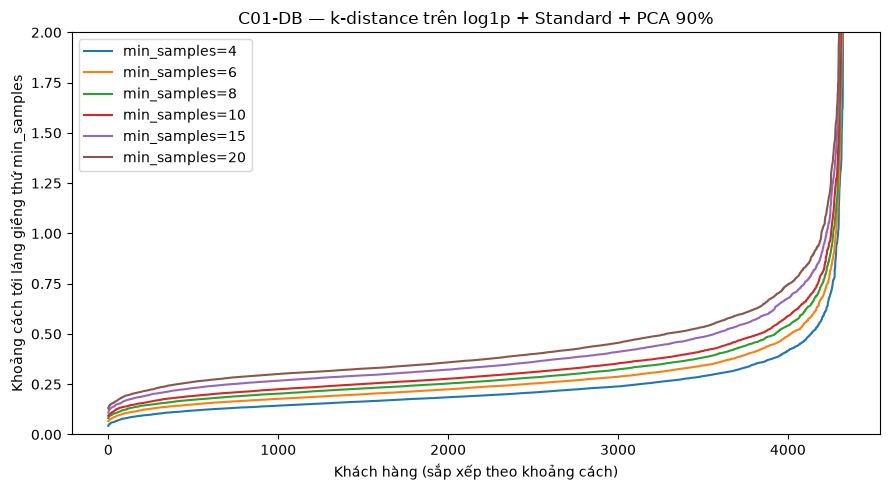

,4,6,8,10,15,20
P50,0.192,0.234,0.262,0.287,0.334,0.370
P90,0.373,0.444,0.488,0.524,0.606,0.673
P95,0.477,0.562,0.626,0.668,0.764,0.841
P99,0.887,1.002,1.108,1.260,1.400,1.550


In [5]:
kdist = {ms: np.sort(NearestNeighbors(n_neighbors=ms).fit(Z).kneighbors(Z)[0][:, -1]) for ms in MIN_SAMPLES_GRID}

fig, ax = plt.subplots(figsize=(9, 5))
for ms, d in kdist.items():
    ax.plot(d, label=f"min_samples={ms}")
ax.set_ylim(0, 2)
ax.set_xlabel("Khách hàng (sắp xếp theo khoảng cách)")
ax.set_ylabel("Khoảng cách tới láng giềng thứ min_samples")
ax.set_title("C01-DB — k-distance trên log1p + Standard + PCA 90%")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=150); plt.show()

pd.DataFrame({ms: np.quantile(d, [0.5, 0.9, 0.95, 0.99]) for ms, d in kdist.items()},
             index=["P50", "P90", "P95", "P99"]).round(3)

**Nhận xét:** Khoảng cách lớn hơn B01 (P95 0,48–0,84 so với 0,15–0,36) do thêm 2 biến; không có khuỷu rõ, cần quét lưới rộng tới eps=3,0.

## Quét lưới eps × min_samples

In [6]:
def run_dbscan(eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Z)
    mask = labels != -1
    sizes = pd.Series(labels[mask]).value_counts()
    k = len(sizes)
    row = {"min_samples": ms, "eps": eps, "n_clusters": k,
           "noise_pct": round(100 * (~mask).mean(), 2),
           "largest_pct": round(100 * sizes.iloc[0] / len(Z), 2) if k else np.nan,
           "smallest": int(sizes.iloc[-1]) if k else 0,
           "silhouette": np.nan, "dbi": np.nan}
    if k >= 2:
        row["silhouette"] = round(silhouette_score(Z[mask], labels[mask]), 4)
        row["dbi"] = round(davies_bouldin_score(Z[mask], labels[mask]), 4)
    return row

grid = pd.DataFrame([run_dbscan(e, m) for m in MIN_SAMPLES_GRID for e in EPS_GRID])
print("Số cấu hình đã chạy:", len(grid))
print("Số cấu hình có >= 2 cụm:", int((grid["n_clusters"] >= 2).sum()))
grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False).head(10)

Số cấu hình đã chạy: 66
Số cấu hình có >= 2 cụm: 24


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
56,20,0.2,4,91.89,4.30,17,0.5194,0.6477
11,6,0.1,11,96.42,1.04,5,0.4374,0.6152
22,8,0.1,5,98.15,0.92,8,0.4348,0.7567
5,4,0.7,2,1.13,98.71,7,0.3889,0.5743
0,4,0.1,62,89.09,2.36,3,0.3831,0.5049
14,6,0.4,2,8.04,91.82,6,0.3691,0.4714
58,20,0.4,2,25.51,73.79,30,0.3590,0.5295
45,15,0.2,4,88.17,8.85,21,0.3494,0.6784
16,6,0.7,3,1.39,98.41,3,0.3391,0.5407
4,4,0.5,3,2.63,97.18,4,0.3173,0.5187


**Nhận xét:** 24/66 cấu hình có ≥ 2 cụm. Cấu hình có Silhouette cao nhất (0,5194, min_samples=20, eps=0,2) lại có nhiễu tới 91,89% — vô nghĩa (gần hết khách bị gán nhiễu). Cần lọc theo điều kiện nhiễu ≤5% trước khi chọn.

## Chọn cấu hình

Cùng quy tắc A01-DB/B01-DB/C04-DB: ≥ 2 cụm, nhiễu ≤ 5% số khách, chọn Silhouette cao nhất.

In [7]:
valid = grid[(grid["n_clusters"] >= MIN_CLUSTERS) & (grid["noise_pct"] <= MAX_NOISE * 100)]
best = valid.sort_values("silhouette", ascending=False).iloc[0]
print("Cấu hình được chọn:")
print(best.to_string())

labels = DBSCAN(eps=best["eps"], min_samples=int(best["min_samples"])).fit_predict(Z)

Cấu hình được chọn:
min_samples     4.0000
eps             0.7000
n_clusters      2.0000
noise_pct       1.1300
largest_pct    98.7100
smallest        7.0000
silhouette      0.3889
dbi             0.5743


**Nhận xét:** Sau khi lọc, chọn `eps=0,7`, `min_samples=4`: 2 cụm, nhiễu 1,13% (49 khách), Silhouette 0,3889, DBI 0,5743 — thấp hơn B01-DB (Silhouette 0,6579) vì không gian 3 chiều phức tạp hơn.

## Đối chiếu B01-DB (dựng lại cùng điều kiện)

Dựng lại B01 (chỉ RFM, không AOV/Diversity) ngay tại đây để so bằng ARI.

In [8]:
Xb = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())]).fit_transform(X[FEATURES_B01])
cum_b = np.cumsum(PCA(svd_solver="full").fit(Xb).explained_variance_ratio_)
n_pc_b = int(np.searchsorted(cum_b, PCA_VAR) + 1)
Z_b01 = PCA(n_components=n_pc_b, svd_solver="full").fit_transform(Xb)
labels_b01 = DBSCAN(eps=0.5, min_samples=4).fit_predict(Z_b01)   # cấu hình B01-DB đã chọn (An, 17-11-2026)

print("Số PC: C01 =", Z.shape[1], "| B01 =", Z_b01.shape[1])
print("ARI (C01-DB vs B01-DB, kể cả nhãn nhiễu):", round(adjusted_rand_score(labels, labels_b01), 4))
print("C01-DB: n_clusters =", int(best["n_clusters"]), "| noise% =", best["noise_pct"])
print("B01-DB: n_clusters =", len(set(labels_b01)) - (1 if -1 in labels_b01 else 0),
      "| noise% =", round(100 * (labels_b01 == -1).mean(), 2))

Số PC: C01 = 3 | B01 = 2
ARI (C01-DB vs B01-DB, kể cả nhãn nhiễu): 0.3645
C01-DB: n_clusters = 2 | noise% = 1.13
B01-DB: n_clusters = 2 | noise% = 0.18


**Nhận xét:** ARI so với B01-DB chỉ **0,3645** — khác biệt rõ, thêm AOV/Diversity đổi cách DBSCAN nhóm khách dù số cụm vẫn là 2. Nhiễu tăng gấp 6 lần (1,13% so với 0,18%).

## Hồ sơ cụm

In [9]:
prof = X.assign(cluster=labels).groupby("cluster").agg(
    customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"), AOV=("AOV", "median"), Diversity=("Diversity", "median"),
    Monetary_sum=("Monetary", "sum"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof.drop(columns="Monetary_sum").round(1)

,customers,Recency,Frequency,Monetary,AOV,Diversity,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,
-1,49,10.0,6.0,6748.8,666.3,67.0,1.1,22.7
0,4271,52.0,2.0,655.8,285.5,35.0,98.7,76.8
1,7,80.0,1.0,4366.8,4008.6,127.0,0.2,0.5


**Nhận xét:** Cụm 0 (4.271 khách, 98,7%) là khách phổ thông, chiếm 76,8% Monetary. Nhóm nhiễu (49 khách, 1,1%) có Monetary cao (6.748,8) và Diversity cao (67 mã hàng), chiếm 22,7% Monetary dù chỉ hơn 1% khách — giống vai trò 'VIP' đã thấy ở các thí nghiệm DBSCAN khác, nhưng lần này nhóm nhiễu lớn hơn hẳn (49 so với 6-26 khách ở A01/B01). Cụm 1 (7 khách) là nhóm AOV cực cao (4.008,6) nhưng Frequency chỉ 1 — khách mua một đơn rất lớn, khác hẳn kiểu VIP mua thường xuyên.

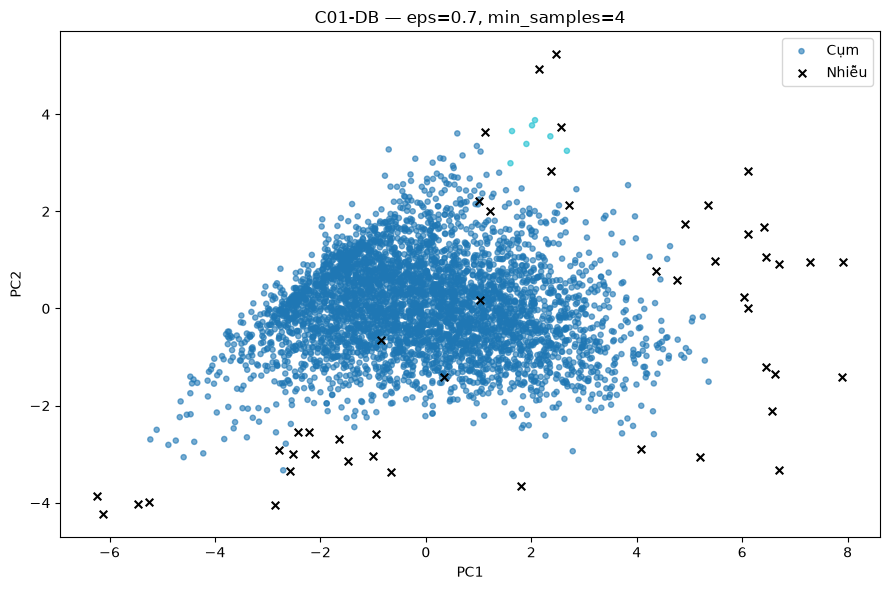

In [10]:
fig, ax = plt.subplots(figsize=(9, 6))
noise = labels == -1
ax.scatter(Z[~noise, 0], Z[~noise, 1], c=labels[~noise], cmap="tab10", s=14, alpha=0.6, label="Cụm")
ax.scatter(Z[noise, 0], Z[noise, 1], c="black", marker="x", s=30, label="Nhiễu")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"C01-DB — eps={best['eps']}, min_samples={int(best['min_samples'])}")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Vẫn một khối lớn và các điểm ngoại lai ở đuôi PC1-PC2, đúng mẫu DBSCAN đã thấy xuyên suốt A/B/C: dựa trên khoảng cách luôn thiên về tách ngoại lai hơn là chia phân khúc cân đối.

## Lưu kết quả

In [11]:
grid.to_csv(OUT / "dbscan_c01_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_c01_labels.csv", index=False)
params = {"experiment": "C01-DB", "features": FEATURES,
          "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes"},
          "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]),
          "n_clusters": int(best["n_clusters"]), "noise_pct": float(best["noise_pct"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "ari_vs_b01_db": float(adjusted_rand_score(labels, labels_b01))}
json.dump(params, open(OUT / "dbscan_c01_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_c01_grid.csv', 'dbscan_c01_labels.csv', 'dbscan_c01_params.json']


**Nhận xét kết luận C01-DB:** Thêm AOV, Diversity làm DBSCAN đổi cách nhóm khách thật sự (ARI=0,36 so với B01) nhưng **không đổi bản chất vấn đề**: vẫn chỉ tách ngoại lai (ở đây là nhóm nhiễu 49 khách Monetary/Diversity cao, chiếm 22,7% Monetary), không phải phân khúc cân đối. Giống kết luận C04-DB của Nguyên (dùng 7 feature, cũng chỉ tách ngoại lai). Nhất quán với phát hiện xuyên suốt: DBSCAN trên không gian PCA của RFM mở rộng luôn thiên về tách outlier; muốn phân khúc cân đối nên dùng KMeans/GMM với biến đổi phù hợp (như B03-KM).